NAME: RACHEAL AUMA

COURSE : MASTER OF SCIENCE IN DATA SCIENCE AND ANALYTICS 

ACCESS NUMBER : B35844

REGISTRATION NUMBER : S25M19/042

Project 2. Concrete Compressive Strength

Task: Predict concrete strength from mixture composition and curing age

Problem Formulation

The problem involves predicting the compressive strength of concrete based on its composition and age. Concrete strength is influenced by different ingredients, including cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate and fine aggregate, as well as the curing age.

The objective is to use the available concrete dataset to develop and evaluate regression models that can accurately predict compressive strength (MPa). The analysis will compare different modelling approaches, starting with a simple mean-based baseline and progressing to linear and non-linear regression models.

The models will be evaluated using appropriate regression metrics, and their prediction errors will be examined to determine how well they generalise to unseen data.

Importing Libraries

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)

Loading the dataset

In [2]:
concrete_data = pd.read_csv (r"C:\Users\HP\Desktop\Mine\School\UCU\Y2\Semester One Y2\Data Mining Modeling & Analytics\CW1\dcs8307-advent-2026-assignment-1-material\Concrete_Data.csv")

In [3]:
concrete_data.head()

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
concrete_data.dtypes

Cement (kg in a m^3 mixture)                         float64
Blast Furnace Slag (kg in a m^3 mixture)             float64
Fly Ash (kg in a m^3 mixture)                        float64
Water (kg in a m^3 mixture)                          float64
Superplasticizer (kg in a m^3 mixture)               float64
Coarse Aggregate (kg in a m^3 mixture)               float64
Fine Aggregate (kg in a m^3 mixture)                 float64
Age (day)                                              int64
Concrete compressive strength (MPa, megapascals)     float64
dtype: object

In [5]:
print ("Number of rows and columns : " , concrete_data.shape)

Number of rows and columns :  (1030, 9)


In [6]:
concrete_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   float64
dtypes: float6

In [7]:
concrete_data.describe().round(2)

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.36,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.75,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.35,968.00,779.51,28.00,34.44
75%,350.00,142.95,118.27,192.00,10.16,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


In [8]:
print (concrete_data.columns.tolist())

['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals) ']


In [9]:
concrete_data.isnull().sum()

Cement (kg in a m^3 mixture)                         0
Blast Furnace Slag (kg in a m^3 mixture)             0
Fly Ash (kg in a m^3 mixture)                        0
Water (kg in a m^3 mixture)                          0
Superplasticizer (kg in a m^3 mixture)               0
Coarse Aggregate (kg in a m^3 mixture)               0
Fine Aggregate (kg in a m^3 mixture)                 0
Age (day)                                            0
Concrete compressive strength (MPa, megapascals)     0
dtype: int64

In [10]:
print ("Number of duplicate records:" , concrete_data.duplicated().sum())

Number of duplicate records: 25


In [11]:
concrete_data[concrete_data.duplicated(keep=False)].sort_values(
    by=concrete_data.columns.tolist()
)

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


In [12]:
# Removing duplicate rows
concrete_data = concrete_data.drop_duplicates()

concrete_data = concrete_data.reset_index(drop=True)

print("Dataset shape after removing duplicates:", concrete_data.shape)

print("Remaining duplicate records:", concrete_data.duplicated().sum())

Dataset shape after removing duplicates: (1005, 9)
Remaining duplicate records: 0


In [13]:
concrete_data.dtypes

Cement (kg in a m^3 mixture)                         float64
Blast Furnace Slag (kg in a m^3 mixture)             float64
Fly Ash (kg in a m^3 mixture)                        float64
Water (kg in a m^3 mixture)                          float64
Superplasticizer (kg in a m^3 mixture)               float64
Coarse Aggregate (kg in a m^3 mixture)               float64
Fine Aggregate (kg in a m^3 mixture)                 float64
Age (day)                                              int64
Concrete compressive strength (MPa, megapascals)     float64
dtype: object

In [16]:
print ("Number of rows and columns : " , concrete_data.shape)

Number of rows and columns :  (1005, 9)


Examining the distribution of the target variable

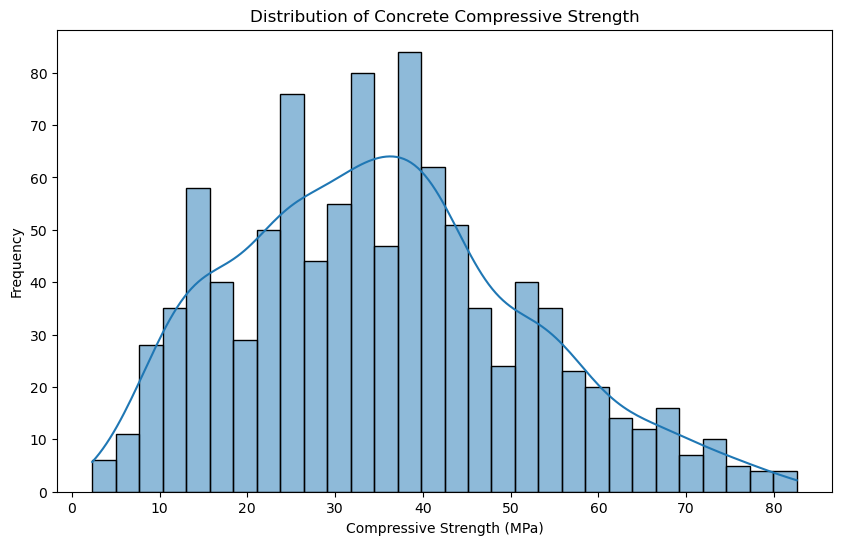

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    concrete_data.iloc[:, -1],
    bins=30,
    kde=True
)

plt.title('Distribution of Concrete Compressive Strength')
plt.xlabel('Compressive Strength (MPa)')
plt.ylabel('Frequency')

plt.show()

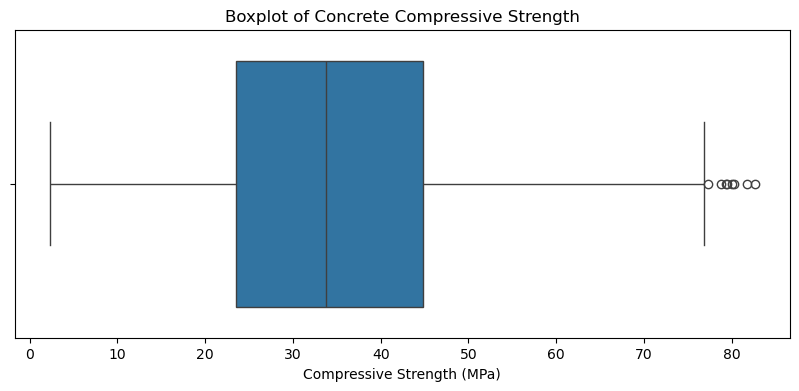

In [15]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=concrete_data.iloc[:, -1])

plt.title('Boxplot of Concrete Compressive Strength')

plt.xlabel('Compressive Strength (MPa)')

plt.show()

EXploring the relationship between input variables and comprehensive strength 

In [17]:
# Calculating correlation matrix
correlation_matrix = concrete_data.corr()

target = concrete_data.columns[-1]

correlation_matrix[target].sort_values(ascending=False)

Concrete compressive strength (MPa, megapascals)     1.000000
Cement (kg in a m^3 mixture)                         0.488283
Superplasticizer (kg in a m^3 mixture)               0.344225
Age (day)                                            0.337371
Blast Furnace Slag (kg in a m^3 mixture)             0.103370
Fly Ash (kg in a m^3 mixture)                       -0.080648
Coarse Aggregate (kg in a m^3 mixture)              -0.144710
Fine Aggregate (kg in a m^3 mixture)                -0.186457
Water (kg in a m^3 mixture)                         -0.269606
Name: Concrete compressive strength (MPa, megapascals) , dtype: float64

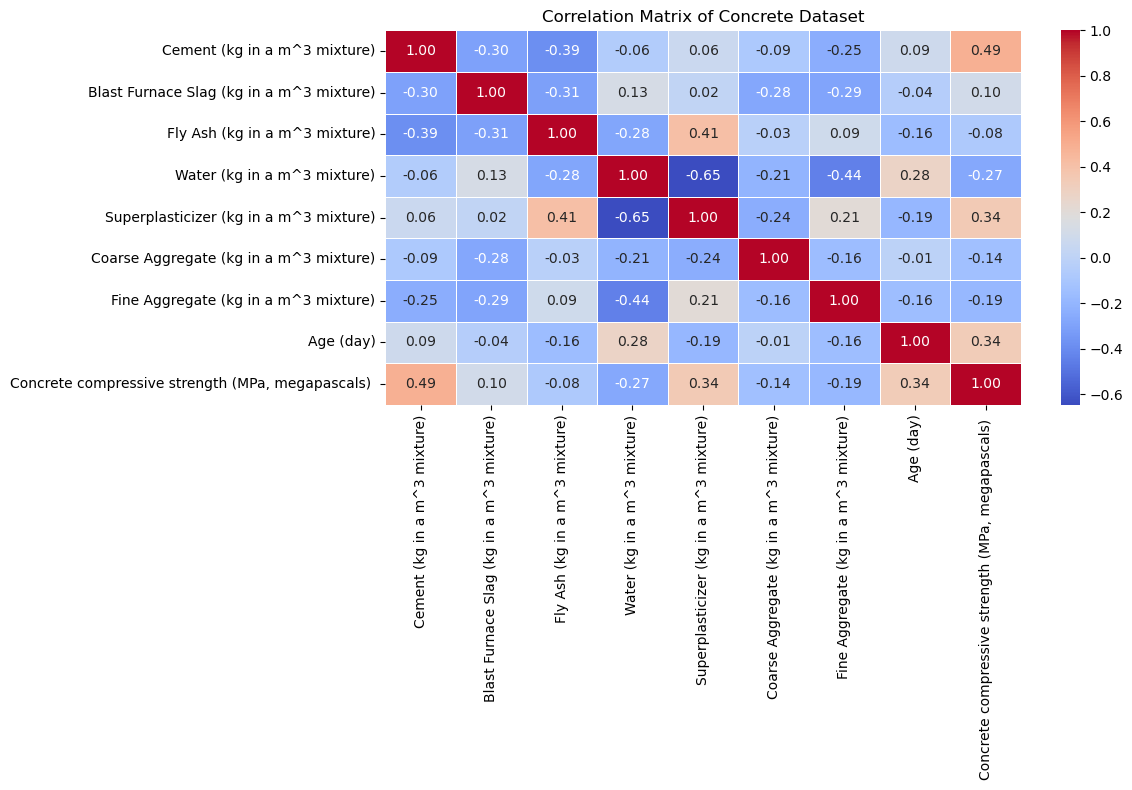

In [18]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Concrete Dataset')

plt.tight_layout()

plt.show()

Examining individual relationships with compressive strength

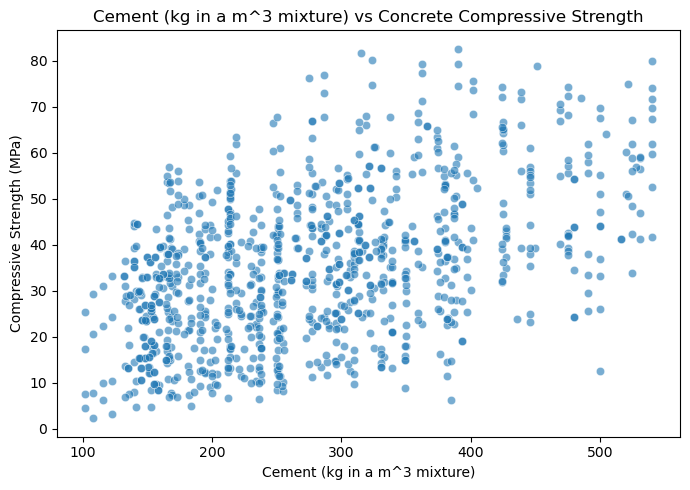

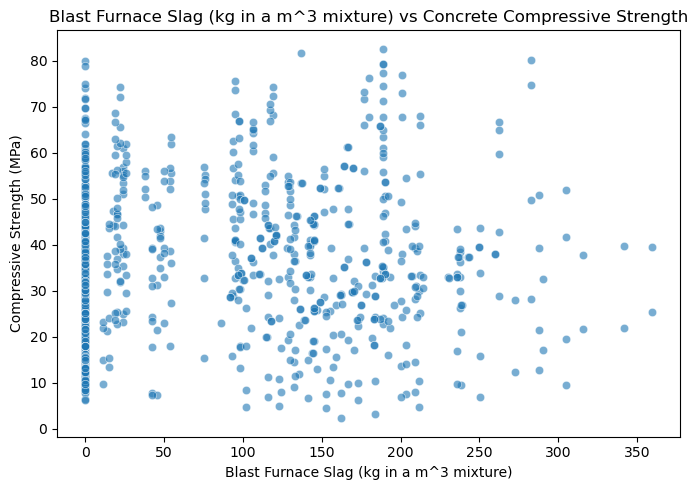

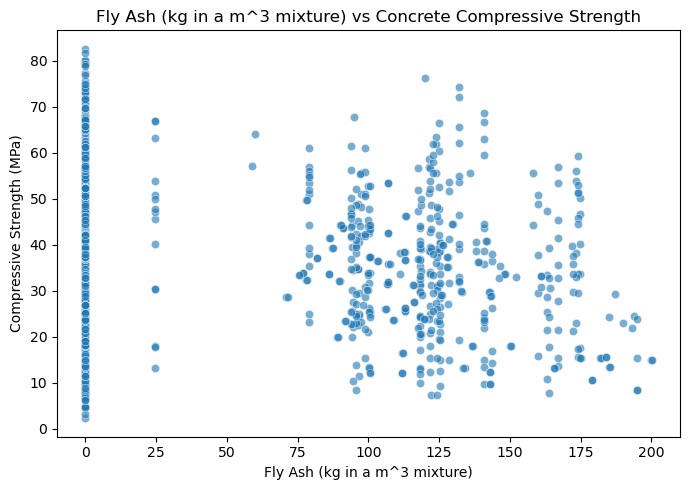

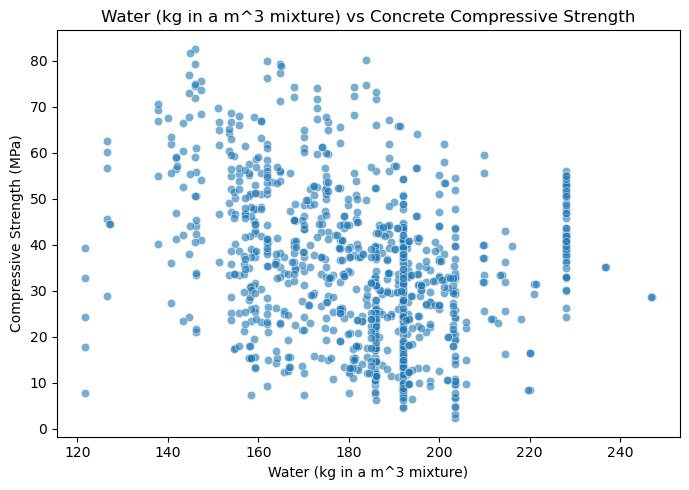

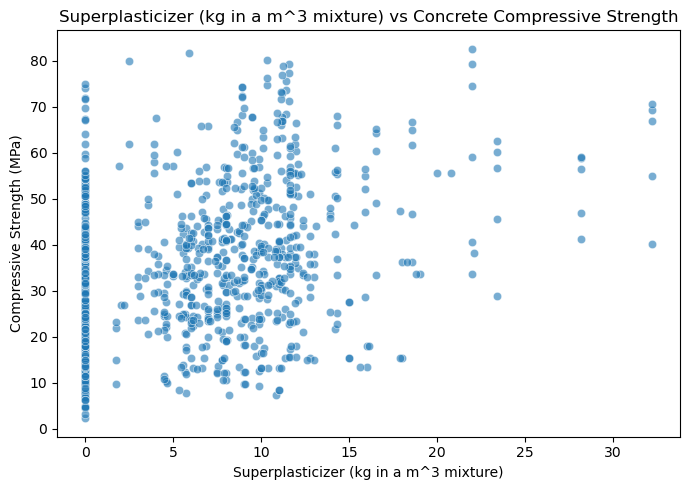

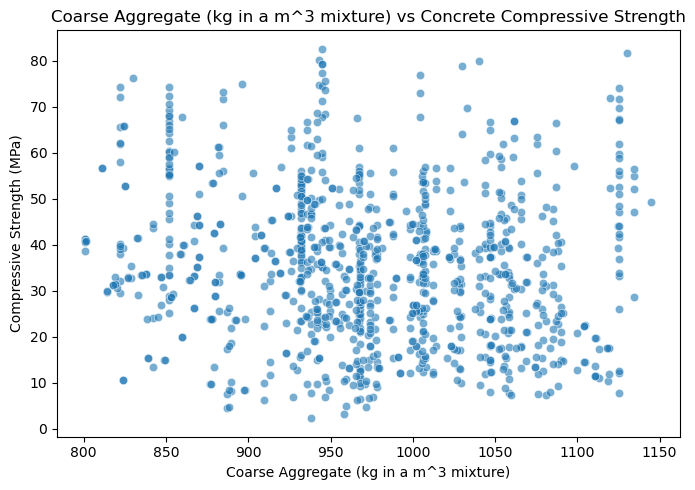

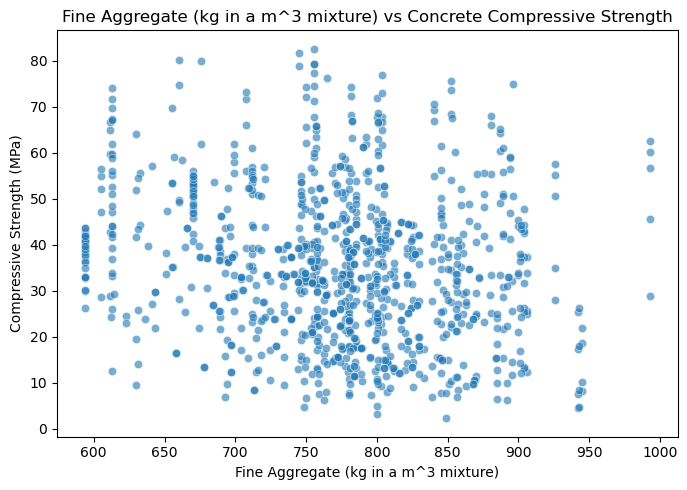

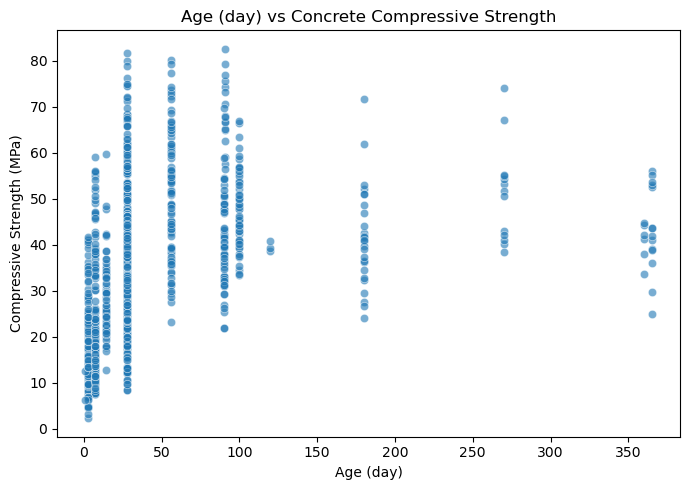

In [19]:
features = concrete_data.columns[:-1]

target = concrete_data.columns[-1]

for feature in features:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=concrete_data,
        x=feature,
        y=target,
        alpha=0.6
    )

    plt.title(f'{feature} vs Concrete Compressive Strength')
    
    plt.xlabel(feature)
    
    plt.ylabel('Compressive Strength (MPa)')
    
    plt.tight_layout()
    
    plt.show()

Examining the distribution of input variables and identifying potential outliers

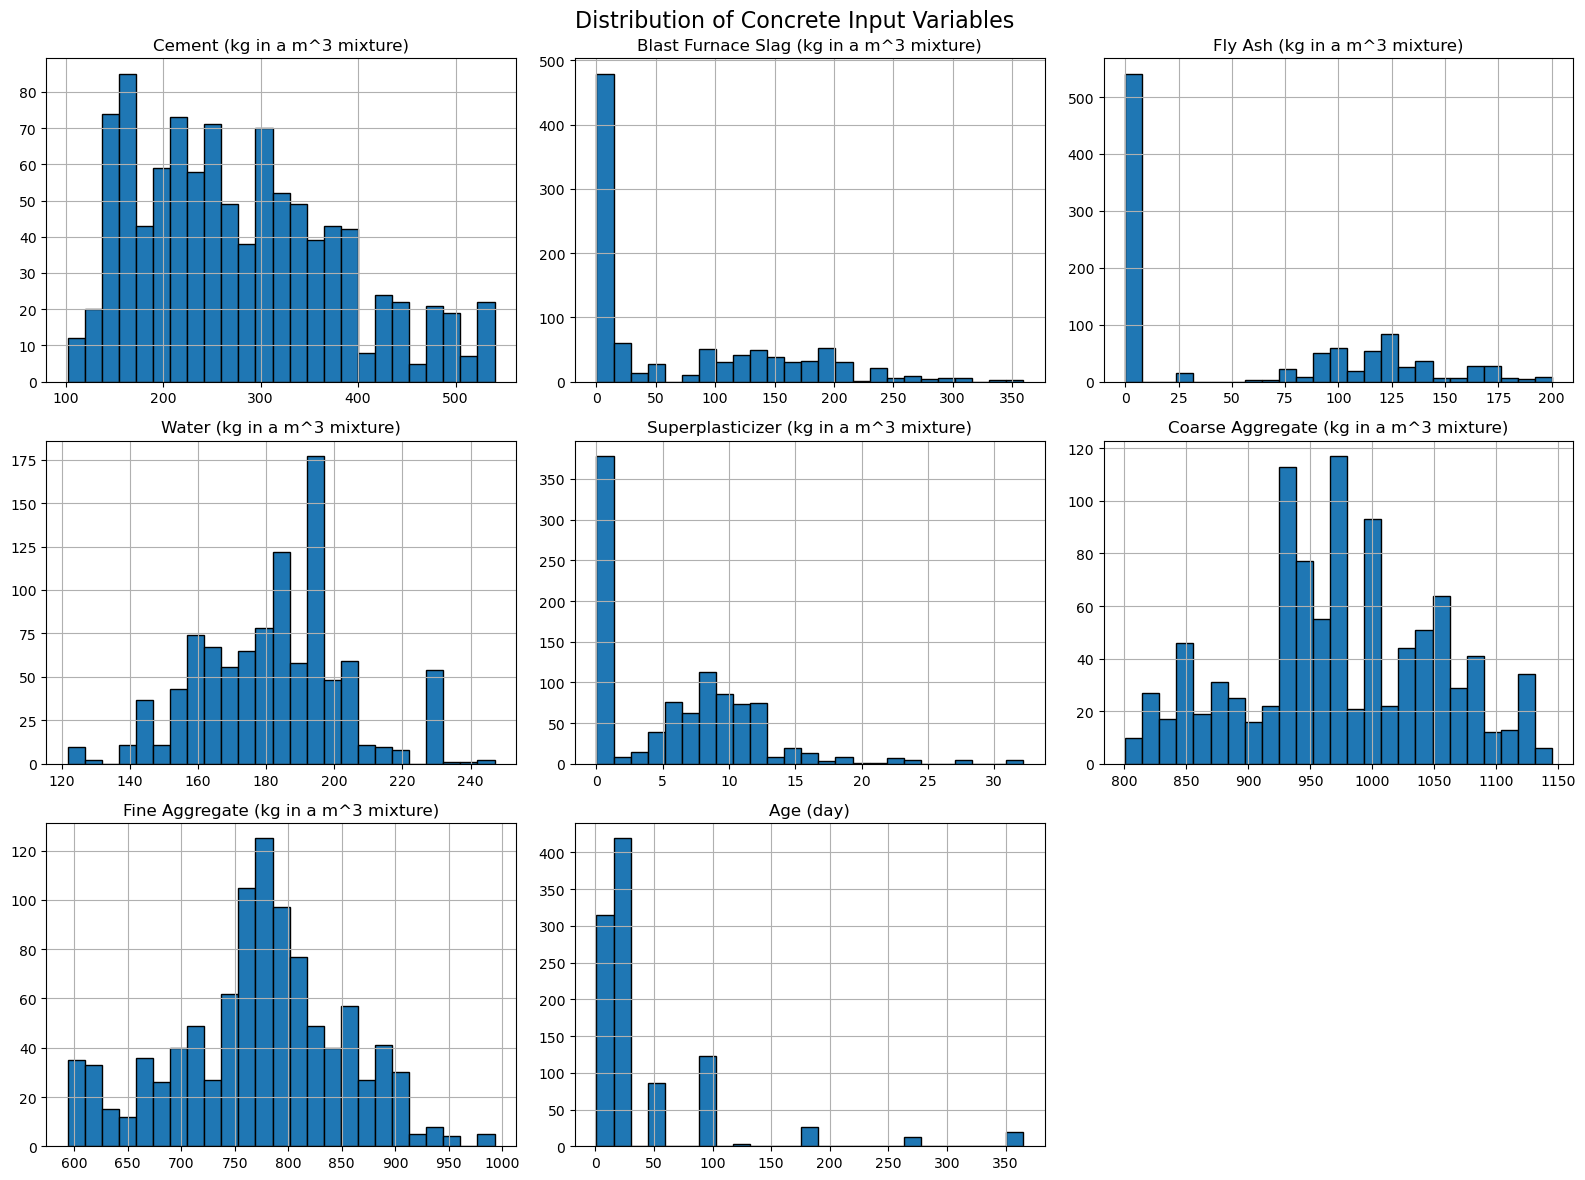

In [20]:
features = concrete_data.columns[:-1]

concrete_data[features].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor='black'
)

plt.suptitle('Distribution of Concrete Input Variables', fontsize=16)

plt.tight_layout()

plt.show()

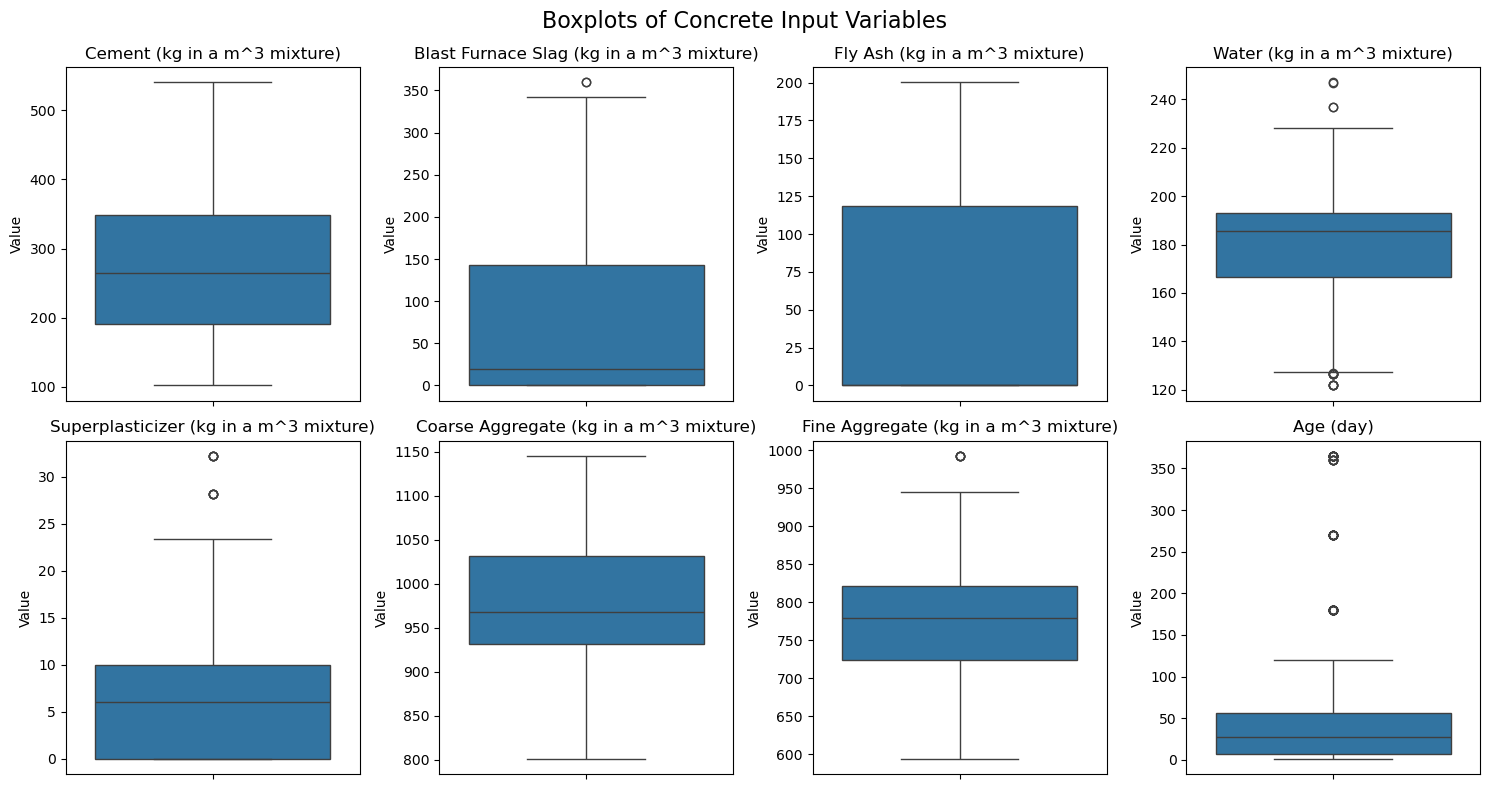

In [21]:
plt.figure(figsize=(15, 8))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=concrete_data[feature])
    plt.title(feature)
    plt.ylabel('Value')

plt.suptitle('Boxplots of Concrete Input Variables', fontsize=16)

plt.tight_layout()

plt.show()

In [22]:
outlier_summary = []

for feature in concrete_data.columns:
    Q1 = concrete_data[feature].quantile(0.25)
    Q3 = concrete_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = concrete_data[
        (concrete_data[feature] < lower_bound) |
        (concrete_data[feature] > upper_bound)
    ]

    outlier_summary.append({
        'Variable': feature,
        'Potential Outliers': len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Variable,Potential Outliers
0,Cement (kg in a m^3 mixture),0
1,Blast Furnace Slag (kg in a m^3 mixture),2
2,Fly Ash (kg in a m^3 mixture),0
3,Water (kg in a m^3 mixture),15
4,Superplasticizer (kg in a m^3 mixture),10
5,Coarse Aggregate (kg in a m^3 mixture),0
6,Fine Aggregate (kg in a m^3 mixture),5
7,Age (day),59
8,"Concrete compressive strength (MPa, megapascals)",8


Data preparation for modelling

In [23]:
# Separating input variables (X) and target variable (y)

X = concrete_data.iloc[:, :-1]

y = concrete_data.iloc[:, -1]

print("Input variables shape:", X.shape)

print("Target variable shape:", y.shape)

Input variables shape: (1005, 8)
Target variable shape: (1005,)


In [24]:
# Splitting into training and testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training dataset:", X_train.shape)

print("Testing dataset:", X_test.shape)

Training dataset: (804, 8)
Testing dataset: (201, 8)


In [25]:
# Standardizing the input variable 

scaler = StandardScaler()

# Fitting scaler on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transforming test data using the training scaler
X_test_scaled = scaler.transform(X_test)

Developing the baseline regression model

In [26]:
# Calculating the mean strength from the training data
mean_strength = y_train.mean()

print("Mean concrete compressive strength:", round(mean_strength, 2), "MPa")

Mean concrete compressive strength: 35.07 MPa


In [27]:
# Predicting the same mean value for every test observation
baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=mean_strength
)

In [28]:
# Evaluating baseline performance

baseline_mae = mean_absolute_error(y_test, baseline_predictions)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(y_test, baseline_predictions)

# Display results
baseline_results = pd.DataFrame({
    'Model': ['Mean Baseline'],
    'MAE': [baseline_mae],
    'RMSE': [baseline_rmse],
    'R2': [baseline_r2]
})

baseline_results.round(4)

,Model,MAE,RMSE,R2
0,Mean Baseline,13.9723,17.2965,-0.0028


Developing the Linear Regression model

In [29]:
# Initialising the Linear Regression model
linear_model = LinearRegression()

# Training the model using scaled training data
linear_model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [30]:
# Predicting concrete compressive strength

linear_predictions = linear_model.predict(X_test_scaled)

In [42]:
# Evaluating model performance

linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(y_test, linear_predictions)

linear_results = pd.DataFrame({
    'Model': ['Linear Regression'],
    'MAE': [linear_mae],
    'RMSE': [linear_rmse],
    'R2': [linear_r2]
})

linear_results.round(4)

,Model,MAE,RMSE,R2
0,Linear Regression,8.896,11.1922,0.5801


In [32]:
# Comparing linear regression against the baseline

comparison = pd.concat(
    [baseline_results, linear_results],
    ignore_index=True
)

comparison.round(4)

,Model,MAE,RMSE,R2
0,Mean Baseline,13.9723,17.2965,-0.0028
1,Linear Regression,8.8960,11.1922,0.5801


Develop a non linear regression model (Random Forest Regression model)

In [33]:
# Training the random forest model

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)

# Training the model using original training data
rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
# Generating predictions 

rf_predictions = rf_model.predict(X_test)

In [41]:
# Evaluating model performance 

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

rf_results = pd.DataFrame({
    'Model': ['Random Forest'],
    'MAE': [rf_mae],
    'RMSE': [rf_rmse],
    'R2': [rf_r2]
})

rf_results.round(4)

,Model,MAE,RMSE,R2
0,Random Forest,3.7173,5.3723,0.9033


In [36]:
# Comparing all models

comparison = pd.concat(
    [baseline_results, linear_results, rf_results],
    ignore_index=True
)

comparison.round(4)

,Model,MAE,RMSE,R2
0,Mean Baseline,13.9723,17.2965,-0.0028
1,Linear Regression,8.8960,11.1922,0.5801
2,Random Forest,3.7173,5.3723,0.9033


Developing the Extra Trees Regression model

In [38]:
# Training the extra trees model

extra_trees_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)

# Training the model
extra_trees_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [39]:
#Generating predictions

extra_trees_predictions = extra_trees_model.predict(X_test)

In [40]:
# EValuating the model

extra_trees_mae = mean_absolute_error(y_test, extra_trees_predictions)

extra_trees_rmse = np.sqrt(
    mean_squared_error(y_test, extra_trees_predictions)
)

extra_trees_r2 = r2_score(y_test, extra_trees_predictions)

extra_trees_results = pd.DataFrame({
    'Model': ['Extra Trees'],
    'MAE': [extra_trees_mae],
    'RMSE': [extra_trees_rmse],
    'R2': [extra_trees_r2]
})

extra_trees_results.round(4)

,Model,MAE,RMSE,R2
0,Extra Trees,3.4972,5.2299,0.9083


In [43]:
# Comparing with all the models

comparison = pd.concat(
    [baseline_results, linear_results, rf_results, extra_trees_results],
    ignore_index=True
)

comparison.round(4)

,Model,MAE,RMSE,R2
0,Mean Baseline,13.9723,17.2965,-0.0028
1,Linear Regression,8.8960,11.1922,0.5801
2,Random Forest,3.7173,5.3723,0.9033
3,Extra Trees,3.4972,5.2299,0.9083


Developing the HistGradientBoosting Regression model

In [44]:
# Training the HistGradientBoosting model

hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

# Training the model
hgb_model.fit(X_train, y_train)

,loss,'squared_error'
,quantile,None
,learning_rate,0.08
,max_iter,200
,max_leaf_nodes,15
,max_depth,None
,min_samples_leaf,20
,l2_regularization,1.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'


In [45]:
# Generating predictions

hgb_predictions = hgb_model.predict(X_test)

In [46]:
# Evaluating model performance 

hgb_mae = mean_absolute_error(y_test, hgb_predictions)

hgb_rmse = np.sqrt(
    mean_squared_error(y_test, hgb_predictions)
)

hgb_r2 = r2_score(y_test, hgb_predictions)

# Display results
hgb_results = pd.DataFrame({
    'Model': ['HistGradientBoosting'],
    'MAE': [hgb_mae],
    'RMSE': [hgb_rmse],
    'R2': [hgb_r2]
})

hgb_results.round(4)

,Model,MAE,RMSE,R2
0,HistGradientBoosting,3.1312,4.6216,0.9284


In [47]:
# Comparing all four predictive models and the baseline

comparison = pd.concat(
    [
        baseline_results,
        linear_results,
        rf_results,
        extra_trees_results,
        hgb_results
    ],
    ignore_index=True
)

comparison.round(4)

,Model,MAE,RMSE,R2
0,Mean Baseline,13.9723,17.2965,-0.0028
1,Linear Regression,8.8960,11.1922,0.5801
2,Random Forest,3.7173,5.3723,0.9033
3,Extra Trees,3.4972,5.2299,0.9083
4,HistGradientBoosting,3.1312,4.6216,0.9284


Conducting residual analysis in order to examine whether the best model's prediction errors are randomly distributed or whether it consistently overestimates or underestimates concrete strength.

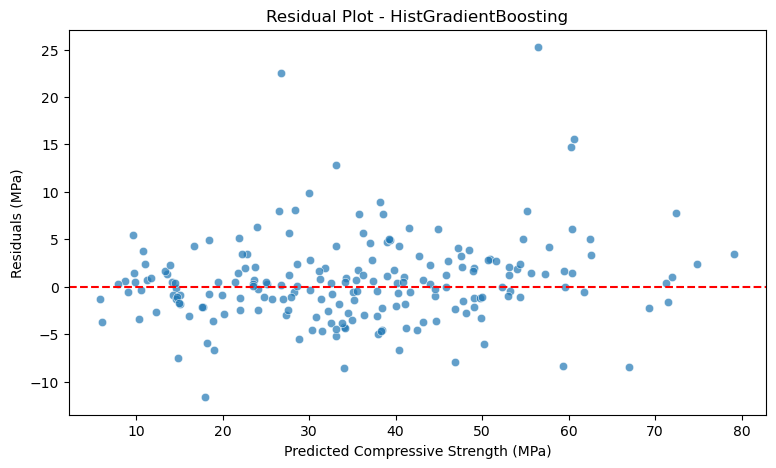

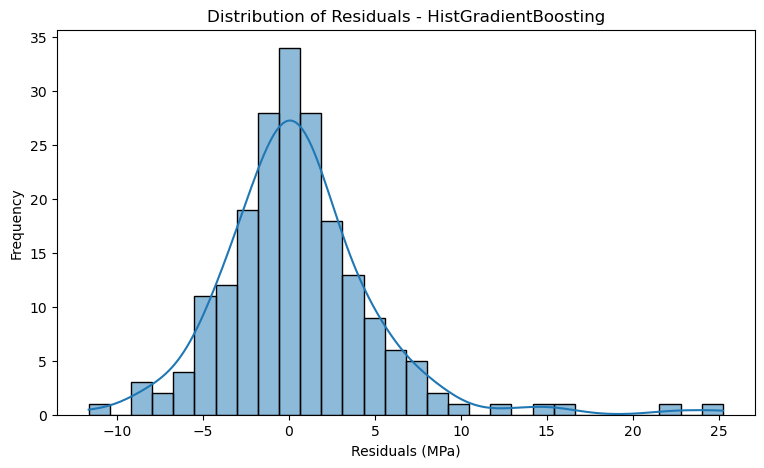

In [48]:
residuals = y_test - hgb_predictions

residual_data = pd.DataFrame({
    'Actual Strength': y_test,
    'Predicted Strength': hgb_predictions,
    'Residual': residuals
})

plt.figure(figsize=(9, 5))
sns.scatterplot(
    x=hgb_predictions,
    y=residuals,
    alpha=0.7
)

plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Compressive Strength (MPa)')
plt.ylabel('Residuals (MPa)')
plt.title('Residual Plot - HistGradientBoosting')
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel('Residuals (MPa)')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals - HistGradientBoosting')
plt.show()

In [49]:
# Calculating absolute prediction errors

residual_data['Absolute Error'] = residual_data['Residual'].abs()

# Displaying the 10 observations with the largest prediction errors
weakest_predictions = residual_data.sort_values(
    by='Absolute Error',
    ascending=False
).head(10)

print("10 Weakest Predictions:")
display(weakest_predictions.round(3))

10 Weakest Predictions:


,Actual Strength,Predicted Strength,Residual,Absolute Error
357,81.751,56.510,25.241,25.241
371,49.249,26.754,22.496,22.496
380,76.235,60.644,15.591,15.591
803,74.987,60.235,14.752,14.752
468,45.898,33.081,12.818,12.818
739,6.267,17.919,-11.651,11.651
898,39.845,29.932,9.913,9.913
101,47.098,38.158,8.940,8.940
544,25.448,34.028,-8.581,8.581
377,58.523,66.993,-8.471,8.471


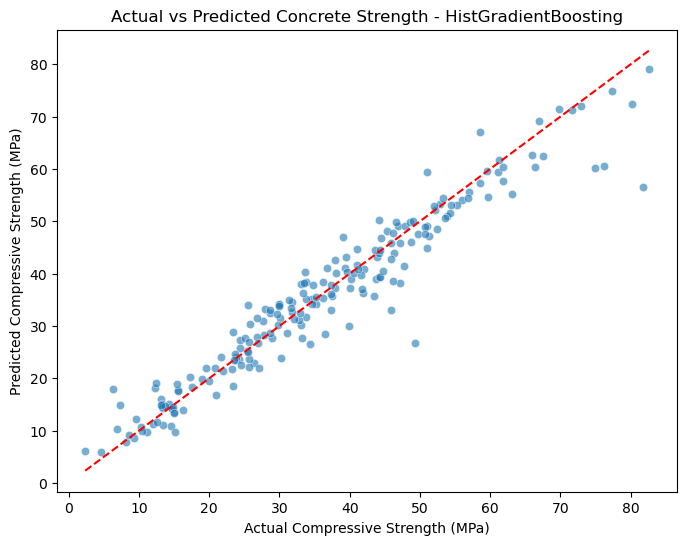

In [50]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=hgb_predictions,
    alpha=0.6
)

min_value = min(y_test.min(), hgb_predictions.min())
max_value = max(y_test.max(), hgb_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--'
)

plt.xlabel('Actual Compressive Strength (MPa)')
plt.ylabel('Predicted Compressive Strength (MPa)')
plt.title('Actual vs Predicted Concrete Strength - HistGradientBoosting')
plt.show()

Feature importance analysis

In [51]:
from sklearn.inspection import permutation_importance

# Calculating permutation importance using the test dataset
permutation_results = permutation_importance(
    hgb_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)


feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': permutation_results.importances_mean,
    'Std': permutation_results.importances_std
})

# Sorting features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance,Std
7,Age (day),8.8885,0.4635
0,Cement (kg in a m^3 mixture),7.1691,0.2918
3,Water (kg in a m^3 mixture),3.4498,0.1680
1,Blast Furnace Slag (kg in a m^3 mixture),2.5902,0.2505
4,Superplasticizer (kg in a m^3 mixture),1.6050,0.0944
6,Fine Aggregate (kg in a m^3 mixture),1.0393,0.0815
5,Coarse Aggregate (kg in a m^3 mixture),0.6279,0.0666
2,Fly Ash (kg in a m^3 mixture),0.1942,0.0371


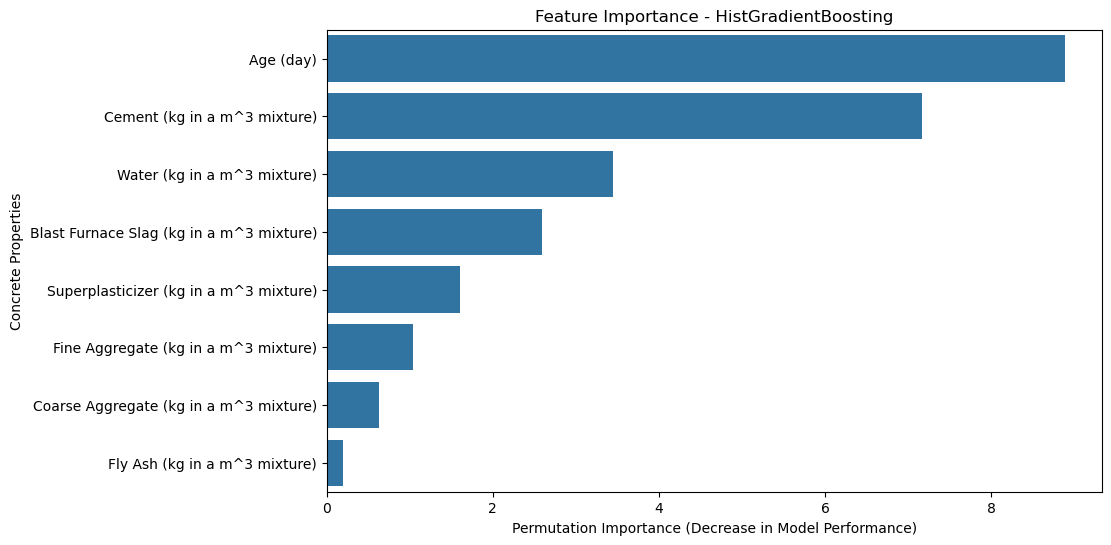

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.xlabel('Permutation Importance (Decrease in Model Performance)')
plt.ylabel('Concrete Properties')
plt.title('Feature Importance - HistGradientBoosting')
plt.show()

In [53]:
# Retrieving the original input features for the weakest predictions

weakest_observations = concrete_data.loc[
    weakest_predictions.index, X.columns
].copy()

weakest_observations['Actual Strength'] = weakest_predictions['Actual Strength']
weakest_observations['Predicted Strength'] = weakest_predictions['Predicted Strength']
weakest_observations['Absolute Error'] = weakest_predictions['Absolute Error']

display(weakest_observations.round(2))

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),Actual Strength,Predicted Strength,Absolute Error
357,315.0,137.0,0.0,145.0,5.90,1130.0,745.0,28,81.75,56.51,25.24
371,200.0,200.0,0.0,190.0,0.00,1145.0,660.0,28,49.25,26.75,22.50
380,275.0,180.0,120.0,162.0,10.35,830.0,765.0,28,76.24,60.64,15.59
803,522.0,0.0,0.0,146.0,0.00,896.0,896.0,28,74.99,60.24,14.75
468,387.0,20.0,94.0,157.0,13.93,938.0,845.0,7,45.90,33.08,12.82
739,385.0,0.0,0.0,186.0,0.00,966.0,763.0,1,6.27,17.92,11.65
898,162.0,207.0,172.0,216.0,10.00,822.0,638.0,28,39.84,29.93,9.91
101,379.5,151.2,0.0,153.9,15.90,1134.3,605.0,7,47.10,38.16,8.94
544,397.0,0.0,0.0,185.7,0.00,1040.6,734.3,7,25.45,34.03,8.58
377,475.0,0.0,0.0,162.0,9.50,1044.0,662.0,28,58.52,66.99,8.47


Evaluating prediction errors across different strength levels

In [54]:
# Grouping test observations into four actual-strength quartiles

residual_data['Strength Group'] = pd.qcut(
    residual_data['Actual Strength'],
    q=4,
    labels=['Low Strength', 'Moderate Strength',
            'High Strength', 'Very High Strength']
)

# Calculating prediction performance within each group
strength_performance = residual_data.groupby(
    'Strength Group',
    observed=False
).agg(
    Number_of_Observations=('Actual Strength', 'count'),
    Mean_Actual_Strength=('Actual Strength', 'mean'),
    MAE=('Absolute Error', 'mean'),
    RMSE=('Residual', lambda x: np.sqrt(np.mean(x**2)))
).reset_index()

display(strength_performance.round(3))

,Strength Group,Number_of_Observations,Mean_Actual_Strength,MAE,RMSE
0,Low Strength,51,14.928,2.239,3.170
1,Moderate Strength,50,29.382,2.898,3.561
2,High Strength,50,41.152,3.085,4.155
3,Very High Strength,50,58.895,4.321,6.758


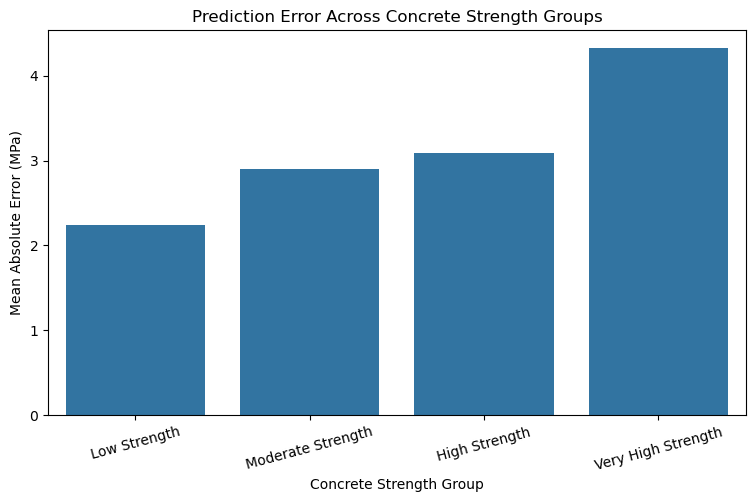

In [55]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=strength_performance,
    x='Strength Group',
    y='MAE'
)

plt.xlabel('Concrete Strength Group')
plt.ylabel('Mean Absolute Error (MPa)')
plt.title('Prediction Error Across Concrete Strength Groups')
plt.xticks(rotation=15)
plt.show()

In [56]:
strength_performance_check = residual_data.groupby(
    'Strength Group',
    observed=False
).agg(
    Observations=('Actual Strength', 'count'),
    MAE=('Absolute Error', 'mean'),
    RMSE=('Residual', lambda x: np.sqrt(np.mean(x**2)))
).reset_index()

display(strength_performance_check.round(3))

,Strength Group,Observations,MAE,RMSE
0,Low Strength,51,2.239,3.170
1,Moderate Strength,50,2.898,3.561
2,High Strength,50,3.085,4.155
3,Very High Strength,50,4.321,6.758


Final model comparison and selection

In [57]:
final_comparison = comparison.copy()

final_comparison = final_comparison.sort_values(
    by='RMSE',
    ascending=True
)

display(final_comparison.round(4))

,Model,MAE,RMSE,R2
4,HistGradientBoosting,3.1312,4.6216,0.9284
3,Extra Trees,3.4972,5.2299,0.9083
2,Random Forest,3.7173,5.3723,0.9033
1,Linear Regression,8.8960,11.1922,0.5801
0,Mean Baseline,13.9723,17.2965,-0.0028


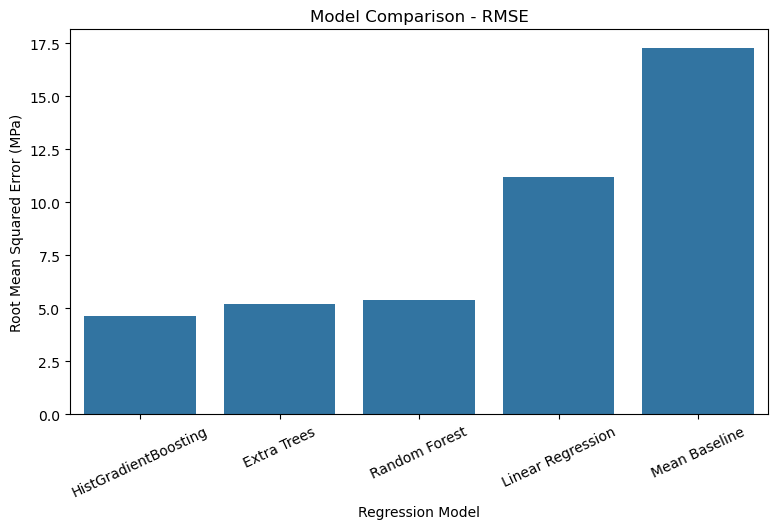

In [58]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison - RMSE')
plt.ylabel('Root Mean Squared Error (MPa)')
plt.xlabel('Regression Model')
plt.xticks(rotation=25)
plt.show()

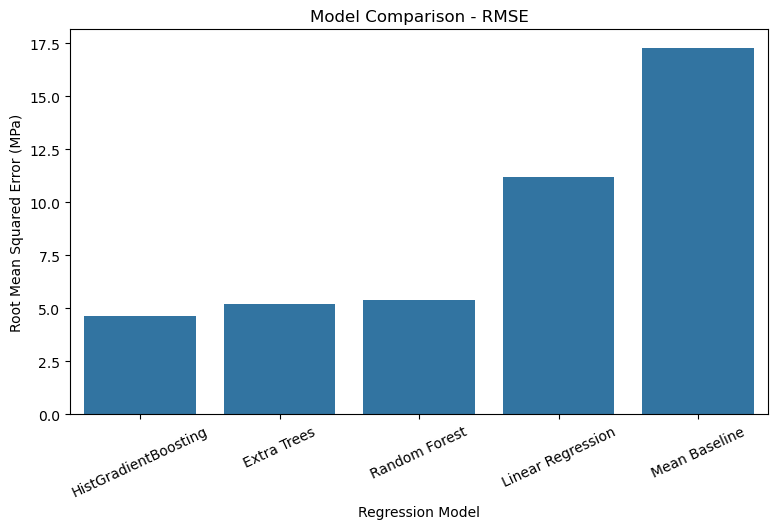

In [59]:
# RMSE comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison - RMSE')
plt.ylabel('Root Mean Squared Error (MPa)')
plt.xlabel('Regression Model')
plt.xticks(rotation=25)
plt.show()

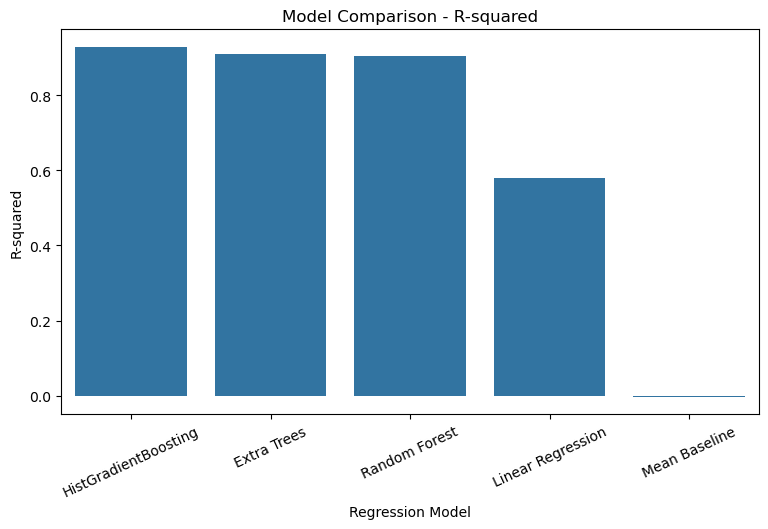

In [60]:
# R² comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='R2'
)

plt.title('Model Comparison - R-squared')
plt.ylabel('R-squared')
plt.xlabel('Regression Model')
plt.xticks(rotation=25)
plt.show()

1. Data exploration, preparation and baseline

The concrete dataset contained 1,030 observations and nine variables: eight input features (cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate and age) and compressive strength as the target. Twenty-five duplicate records were identified and removed, leaving 1,005 observations. No missing values were indicated in the dataset checks. Potential outliers identified using the IQR method were retained because they could represent legitimate variations in concrete mixtures and curing ages.

The data was divided into 80% training and 20% testing sets. Standardisation was applied for Linear Regression, with the scaler fitted on the training data only. A mean-prediction baseline was established, recording an MAE of 13.9723 MPa, RMSE of 17.2965 MPa and R² of -0.0028. This provided a benchmark against which the other models were evaluated.

2. Comparison of linear and non-linear models, residuals and weakest predictions

Linear Regression achieved an MAE of 8.8960 MPa, RMSE of 11.1922 MPa and R² of 0.5801. The non-linear ensemble models performed substantially better. HistGradientBoosting was the best model, recording an MAE of 3.1312 MPa, RMSE of 4.6216 MPa and R² of 0.9284. Extra Trees and Random Forest followed with R² values of 0.9083 and 0.9033, respectively.

Residual analysis showed prediction errors in both directions. The largest absolute prediction error was 25.241 MPa. The model also performed less accurately for very high-strength concrete: its MAE increased from 2.239 MPa for low-strength concrete to 4.321 MPa for very high-strength concrete. Permutation importance identified age (8.8885) and cement (7.1691) as the two most influential predictors.

These findings support selecting HistGradientBoosting as the preferred model, although its performance on individual high-strength samples requires further improvement. The results are consistent with literature describing concrete strength as a complex, non-linear function of its ingredients and curing age (Yeh, 1998; UCI, n.d.).

3. Does predictive association between cement content and strength prove what will happen if we change the mixture?

No. Predictive association does not establish causation.

Although cement was the second most important predictor in our model, this only indicates that cement content provides useful information for predicting compressive strength. It does not prove that increasing cement alone will produce a particular increase in strength.

Concrete strength also depends on other factors, including water content, curing age, supplementary cementitious materials and interactions between mixture components. Changing cement content may also alter the overall mixture proportions. Therefore, the effect of an actual change cannot be established from feature importance or predictive modelling alone.

To establish causality, controlled experiments should be conducted in which cement content is deliberately varied while other relevant conditions are controlled. This would help determine the actual effect of changing cement content on compressive strength (Yeh, 1998; Young et al., 2019).

Discussion of Findings

The analysis demonstrated that concrete compressive strength can be predicted effectively using machine learning techniques. The non-linear ensemble models outperformed Linear Regression, indicating that the relationship between concrete ingredients, curing age and compressive strength is complex and not entirely linear.

HistGradientBoosting achieved the best performance, with an R² of 0.9284, MAE of 3.1312 MPa and RMSE of 4.6216 MPa. Feature importance analysis identified concrete age and cement content as the most influential predictors, followed by water and blast furnace slag. However, prediction errors increased for higher-strength concrete, suggesting that the model is less accurate for some high-strength mixtures.

Limitations
                                                                                                                                                                                                                                                                                                                                                                                       
- The dataset contained only 1,005 observations after duplicate removal, which may limit the model's ability to generalise to a wider range of concrete mixtures.
- The analysis relied on a single 80:20 train-test split, meaning performance may vary with different data partitions.
- Some observations had relatively large prediction errors, with the largest absolute error being 25.241 MPa.
- The dataset may not capture all real-world factors affecting concrete strength, such as environmental conditions, material quality and variations in construction practices.
- Predictive associations do not establish causal relationships between individual ingredients and concrete strength.

Recommendations
                                                                                                                                                                                                                                                                                                                                                                                       
- HistGradientBoosting should be prioritised for predicting concrete compressive strength because it achieved the best overall evaluation results.
- Further model tuning and cross-validation should be undertaken to assess model stability and improve generalisation.
- Additional concrete samples, particularly representing high-strength mixtures, should be included to improve prediction accuracy across different strength ranges.
- Future studies should investigate controlled experiments to establish the causal effects of changing cement, water and other mixture proportions.
- The model should be validated using independent real-world concrete test data before being adopted for engineering or construction decisions.

Conclusion
    
The study successfully developed and evaluated regression models for predicting concrete compressive strength using its mixture composition and curing age. HistGradientBoosting emerged as the best-performing model, explaining 92.84% of the variation in compressive strength, with an average absolute prediction error of approximately 3.13 MPa. The findings demonstrate the value of non-linear machine learning approaches for concrete strength prediction. Nevertheless, the model's limitations, particularly its weaker performance on some high-strength samples, highlight the need for further validation and improvement before practical application.

REFERENCES

1. UCI Machine Learning Repository. (n.d.). Concrete Compressive Strength Dataset. Dataset and description.



2. Yeh, I.-C. (1998). Modeling of strength of high-performance concrete using artificial neural networks. Cement and Concrete Research, 28(12), 1797–1808. 


3. Young, B. A., Hall, A., Pilon, L., Gupta, P., & Sant, G. (2019). Can the compressive strength of concrete be estimated from knowledge of the mixture proportions? New insights from statistical analysis and machine learning methods. Cement and Concrete Research. 